# Papaya Disease Classification — Otsu's Thresholding
Otsu's method automatically selects the optimal global threshold by minimising the intra-class intensity variance. It adapts to each image's histogram, making it more robust than a fixed threshold.

## 1. Setup and Libraries

In [1]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from skimage.io import imread
from skimage.transform import resize
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score
)

## 2. Otsu Thresholding Segmentation
OpenCV's `cv2.THRESH_OTSU` flag computes the threshold automatically for each image.

In [2]:
categories = ['Diseased', 'Healthy']

train_dir = '..\\Augmentation\\Augmented DataSet\\Train'
test_dir  = '..\\Augmentation\\Augmented DataSet\\Test'


def load_split(base_dir, categories):
    features = []
    labels = []

    for label_idx, cat in enumerate(categories):

        folder = os.path.join(base_dir, cat)

        print(f'Loading {cat} from {base_dir}')

        for fname in os.listdir(folder):

            img = imread(os.path.join(folder, fname))

            # grayscale
            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

            # Gaussian Blur
            gray = cv2.GaussianBlur(gray, (7, 7), 0)

            # Adaptive Mean Thresholding
            seg = cv2.adaptiveThreshold(gray,255,cv2.ADAPTIVE_THRESH_MEAN_C,cv2.THRESH_BINARY,11,2)

            seg = resize(seg, (64, 64))

            features.append(seg.flatten())
            labels.append(label_idx)

        print(f'Done: {cat}')

    return np.array(features), np.array(labels)


X_train, y_train = load_split(train_dir, categories)
X_test, y_test = load_split(test_dir, categories)

print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Loading Diseased from ..\Augmentation\Augmented DataSet\Train
Done: Diseased
Loading Healthy from ..\Augmentation\Augmented DataSet\Train
Done: Healthy
Loading Diseased from ..\Augmentation\Augmented DataSet\Test
Done: Diseased
Loading Healthy from ..\Augmentation\Augmented DataSet\Test
Done: Healthy
Training Shape : (5600, 4096)
Testing Shape  : (1400, 4096)


In [3]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

## 4. Evaluation Helper
A reusable function that prints a classification report, shows a confusion-matrix heatmap, and returns the four key metrics.

In [4]:
def assess_model(name, clf, X_tr, y_tr, X_te, y_te, label_names):
    y_pred = clf.predict(X_te)
    acc  = accuracy_score(y_te, y_pred)
    prec = precision_score(y_te, y_pred, average='weighted')
    rec  = recall_score(y_te, y_pred, average='weighted')
    f1   = f1_score(y_te, y_pred, average='weighted')
    tr_acc = accuracy_score(y_tr, clf.predict(X_tr))

    print(f'\n=== {name} ===')
    print(classification_report(y_te, y_pred, target_names=label_names))
    print(f'  Test Accuracy  : {acc*100:.2f}%')
    print(f'  Train Accuracy : {tr_acc*100:.2f}%')
    print(f'  Precision      : {prec*100:.2f}%')
    print(f'  Recall         : {rec*100:.2f}%')
    print(f'  F1-Score       : {f1*100:.2f}%')

    cm = confusion_matrix(y_te, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm / cm.sum(), annot=True, fmt='.2%',
                cmap='YlOrRd', xticklabels=label_names, yticklabels=label_names)
    plt.title(f'{name} — Confusion Matrix')
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

    return acc, prec, rec, f1


## 5. Classifiers
We train several classifiers and compare their performance on the segmented features.

### 5.1 Decision Tree


=== Decision Tree ===
              precision    recall  f1-score   support

    Diseased       0.65      0.66      0.65       700
     Healthy       0.65      0.64      0.65       700

    accuracy                           0.65      1400
   macro avg       0.65      0.65      0.65      1400
weighted avg       0.65      0.65      0.65      1400

  Test Accuracy  : 65.07%
  Train Accuracy : 100.00%
  Precision      : 65.08%
  Recall         : 65.07%
  F1-Score       : 65.07%


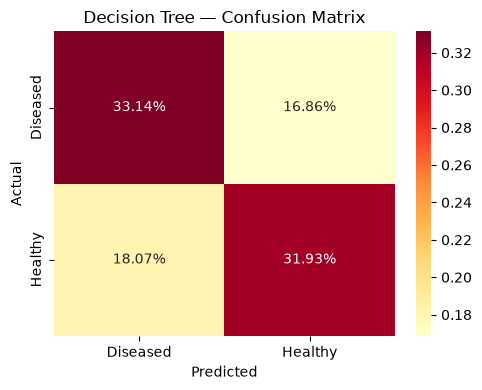

In [5]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(max_depth=25, random_state=42)
dt.fit(X_train, y_train)
acc_dt, prec_dt, rec_dt, f1_dt = assess_model('Decision Tree', dt, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### 5.2 Naive Bayes


=== Naive Bayes ===
              precision    recall  f1-score   support

    Diseased       0.87      0.79      0.83       700
     Healthy       0.81      0.88      0.84       700

    accuracy                           0.83      1400
   macro avg       0.84      0.83      0.83      1400
weighted avg       0.84      0.83      0.83      1400

  Test Accuracy  : 83.36%
  Train Accuracy : 87.98%
  Precision      : 83.65%
  Recall         : 83.36%
  F1-Score       : 83.32%


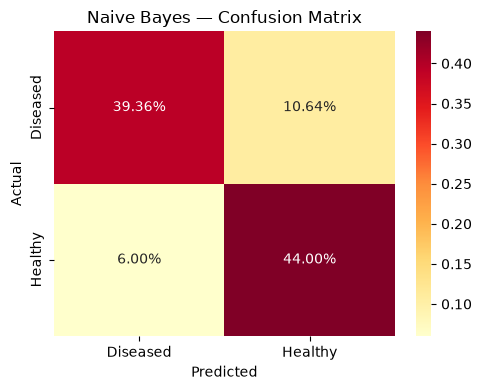

In [6]:
from sklearn.naive_bayes import GaussianNB

nb = GaussianNB()
nb.fit(X_train, y_train)
acc_nb, prec_nb, rec_nb, f1_nb = assess_model('Naive Bayes', nb, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### 5.3 Logistic Regression


=== Logistic Regression ===
              precision    recall  f1-score   support

    Diseased       0.77      0.70      0.73       700
     Healthy       0.72      0.79      0.75       700

    accuracy                           0.74      1400
   macro avg       0.75      0.74      0.74      1400
weighted avg       0.75      0.74      0.74      1400

  Test Accuracy  : 74.43%
  Train Accuracy : 100.00%
  Precision      : 74.61%
  Recall         : 74.43%
  F1-Score       : 74.38%


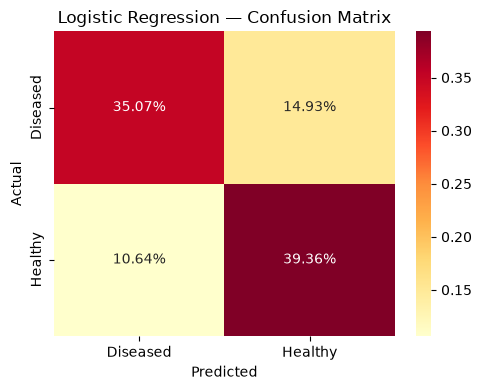

In [7]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(solver='liblinear', random_state=42)
lr.fit(X_train, y_train)
acc_lr, prec_lr, rec_lr, f1_lr = assess_model('Logistic Regression', lr, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### 5.4 K-Nearest Neighbors


=== KNN ===
              precision    recall  f1-score   support

    Diseased       0.92      0.38      0.54       700
     Healthy       0.61      0.97      0.75       700

    accuracy                           0.67      1400
   macro avg       0.76      0.67      0.64      1400
weighted avg       0.76      0.67      0.64      1400

  Test Accuracy  : 67.21%
  Train Accuracy : 81.07%
  Precision      : 76.27%
  Recall         : 67.21%
  F1-Score       : 64.12%


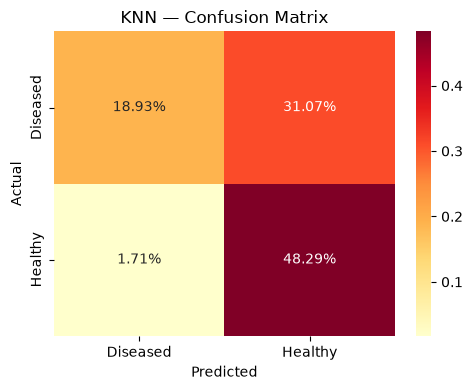

In [8]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train, y_train)
acc_knn, prec_knn, rec_knn, f1_knn = assess_model('KNN', knn, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### 5.5 Random Forest


=== Random Forest ===
              precision    recall  f1-score   support

    Diseased       0.87      0.82      0.84       700
     Healthy       0.83      0.87      0.85       700

    accuracy                           0.85      1400
   macro avg       0.85      0.85      0.85      1400
weighted avg       0.85      0.85      0.85      1400

  Test Accuracy  : 84.71%
  Train Accuracy : 99.32%
  Precision      : 84.82%
  Recall         : 84.71%
  F1-Score       : 84.70%


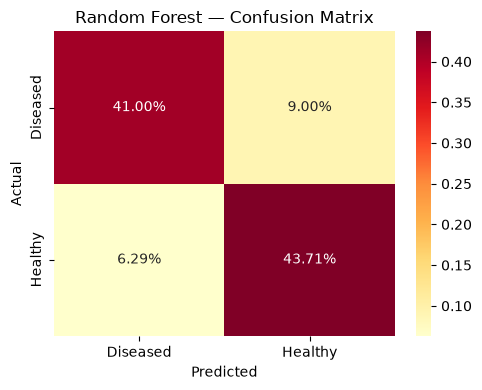

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, min_samples_split=12,
                             min_samples_leaf=5, max_features='log2', random_state=42)
rf.fit(X_train, y_train)
acc_rf, prec_rf, rec_rf, f1_rf = assess_model('Random Forest', rf, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

### 5.6 Voting Classifiers


=== Soft Voting ===
              precision    recall  f1-score   support

    Diseased       0.86      0.72      0.78       700
     Healthy       0.76      0.89      0.82       700

    accuracy                           0.80      1400
   macro avg       0.81      0.80      0.80      1400
weighted avg       0.81      0.80      0.80      1400

  Test Accuracy  : 80.21%
  Train Accuracy : 99.98%
  Precision      : 81.11%
  Recall         : 80.21%
  F1-Score       : 80.07%


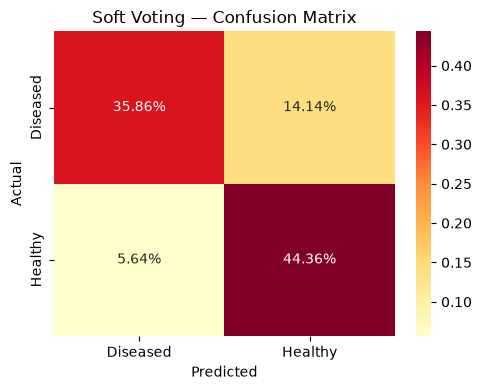


=== Hard Voting ===
              precision    recall  f1-score   support

    Diseased       0.83      0.80      0.81       700
     Healthy       0.80      0.84      0.82       700

    accuracy                           0.82      1400
   macro avg       0.82      0.82      0.82      1400
weighted avg       0.82      0.82      0.82      1400

  Test Accuracy  : 81.71%
  Train Accuracy : 99.21%
  Precision      : 81.77%
  Recall         : 81.71%
  F1-Score       : 81.71%


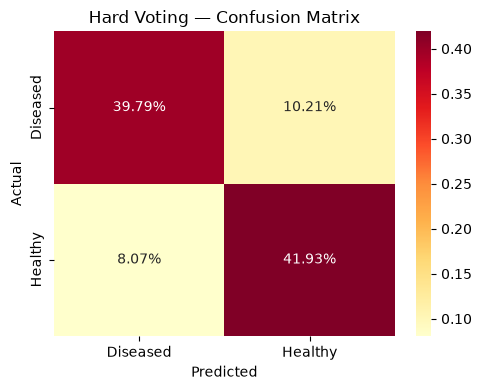

In [10]:
from sklearn.ensemble import VotingClassifier

estimators = [('nb', nb), ('dt', dt), ('knn', knn), ('lr', lr)]

soft_vc = VotingClassifier(estimators=estimators, voting='soft')
soft_vc.fit(X_train, y_train)
acc_sv, prec_sv, rec_sv, f1_sv = assess_model('Soft Voting', soft_vc, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

hard_vc = VotingClassifier(estimators=estimators, voting='hard')
hard_vc.fit(X_train, y_train)
acc_hv, prec_hv, rec_hv, f1_hv = assess_model('Hard Voting', hard_vc, X_train, y_train, X_test, y_test, ['Diseased', 'Healthy'])

## 6. Performance Comparison Chart
Grouped bar chart across Accuracy, Precision, Recall, and F1-Score for all classifiers.

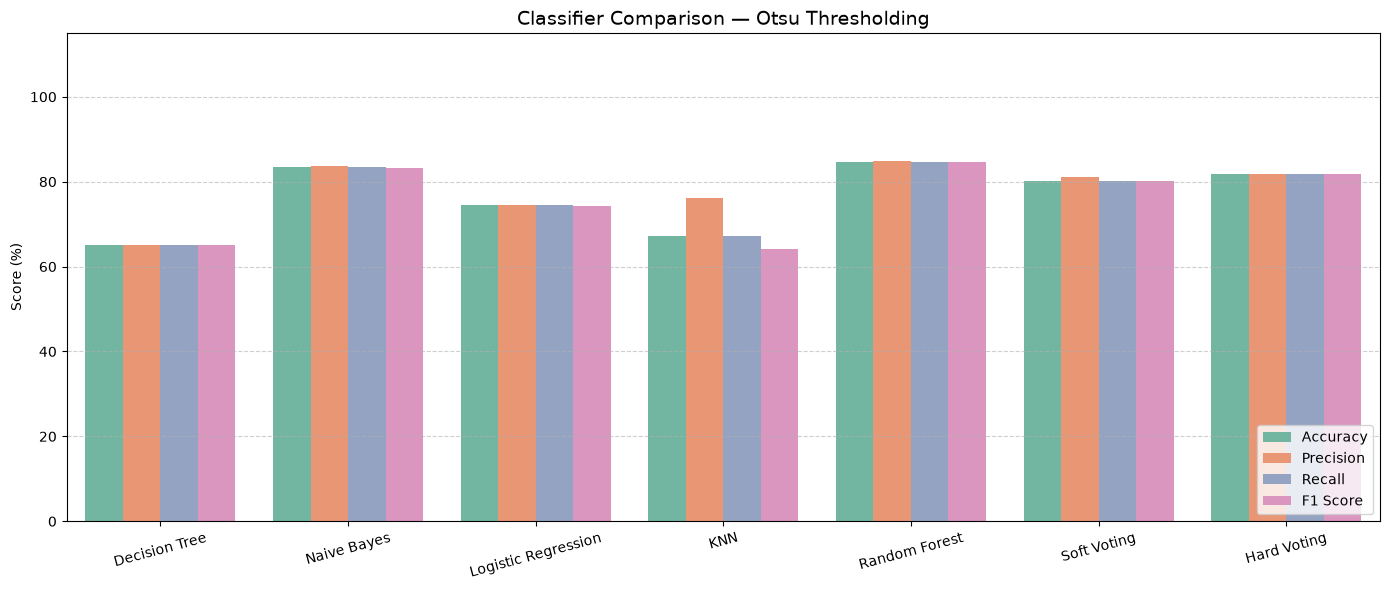

In [12]:
model_names = ['Decision Tree', 'Naive Bayes', 'Logistic Regression', 'KNN', 'Random Forest', 'Soft Voting', 'Hard Voting']
accs  = [acc_dt,  acc_nb,  acc_lr,  acc_knn,  acc_rf,  acc_sv,  acc_hv]
precs = [prec_dt, prec_nb, prec_lr, prec_knn, prec_rf, prec_sv, prec_hv]
recs  = [rec_dt,  rec_nb,  rec_lr,  rec_knn,  rec_rf,  rec_sv,  rec_hv]
f1s   = [f1_dt,   f1_nb,   f1_lr,   f1_knn,   f1_rf,   f1_sv,   f1_hv]

df_cmp = pd.DataFrame({
    'Classifier': model_names,
    'Accuracy': accs, 'Precision': precs,
    'Recall': recs, 'F1 Score': f1s
})

df_melt = df_cmp.melt(id_vars='Classifier', var_name='Metric', value_name='Score')
df_melt['Score'] *= 100

plt.figure(figsize=(14, 6))
sns.barplot(x='Classifier', y='Score', hue='Metric', data=df_melt, palette='Set2')
plt.title('Classifier Comparison — Otsu Thresholding', fontsize=14)
plt.ylabel('Score (%)')
plt.xlabel('')
plt.ylim(0, 115)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.legend(loc='lower right')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 7. Radar Chart — Top vs Bottom Model
A radar (spider) chart comparing the best-performing and worst-performing classifiers across four metrics.

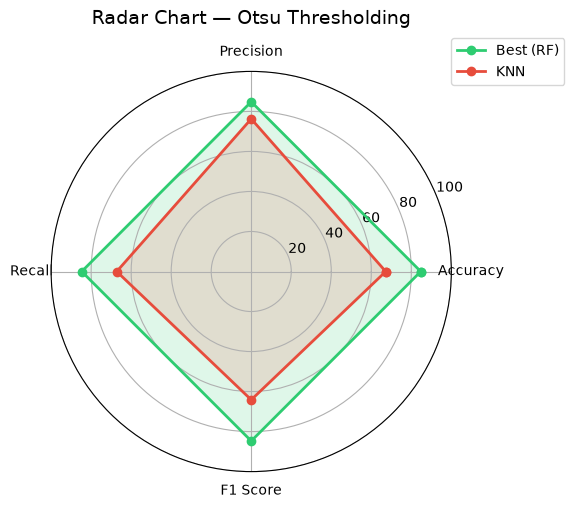

In [13]:
import numpy as np
import matplotlib.pyplot as plt

metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
scores = {
    'Best (RF)':  [acc_rf, prec_rf, rec_rf, f1_rf],
    'KNN':        [acc_knn, prec_knn, rec_knn, f1_knn],
}

angles = np.linspace(0, 2 * np.pi, len(metrics), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))
colors = ['#2ecc71', '#e74c3c']
for (label, vals), color in zip(scores.items(), colors):
    vals = [v * 100 for v in vals] + [vals[0] * 100]
    ax.plot(angles, vals, 'o-', linewidth=2, label=label, color=color)
    ax.fill(angles, vals, alpha=0.15, color=color)

ax.set_thetagrids(np.degrees(angles[:-1]), metrics)
ax.set_ylim(0, 100)
ax.set_title('Radar Chart — Otsu Thresholding', size=14, pad=15)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.show()

## 8. Live Prediction on Sample Papaya Image
We pick a sample from the Diseased folder, apply Otsu's Thresholding segmentation, and classify it.

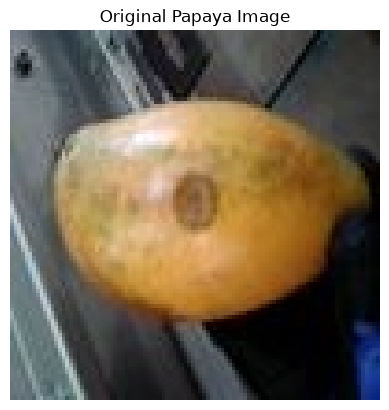

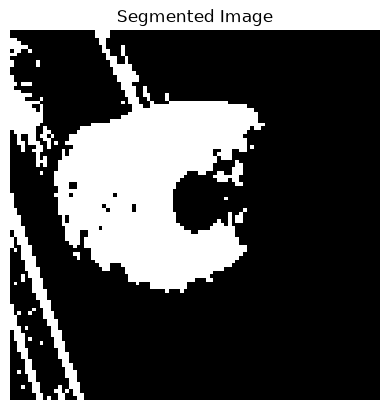

Prediction Probabilities:
Diseased: 85.18%
Healthy: 14.82%

Final Prediction: The Disease image is classified as Diseased


In [16]:
import random
categories = ['Diseased', 'Healthy']

sample_dir = os.path.join(test_dir, 'Diseased')
sample_file = random.choice(os.listdir(sample_dir))
sample_path = os.path.join(sample_dir, sample_file)

sample_img = imread(sample_path)

plt.imshow(sample_img)
plt.axis('off')
plt.title('Original Papaya Image')
plt.show()


gray_sample = cv2.cvtColor(sample_img, cv2.COLOR_BGR2GRAY)
blurred_sample = cv2.GaussianBlur(gray_sample, (7, 7), 0)   

seg_sample = cv2.threshold(gray_sample, 127, 255, cv2.THRESH_BINARY)[1]


plt.imshow(seg_sample, cmap='gray')
plt.axis('off')
plt.title('Segmented Image')
plt.show()

vectorized_sample = resize(seg_sample, (64, 64)).flatten().reshape(1, -1)
scaled_sample = scaler.transform(vectorized_sample)   
prediction_input = scaled_sample


predicted_idx = rf.predict(prediction_input)[0]
probabilities = rf.predict_proba(prediction_input)[0]

print("Prediction Probabilities:")
for idx, cat_name in enumerate(categories):
    print(f"{cat_name}: {probabilities[idx] * 100:.2f}%")

print(f"\nFinal Prediction: The Disease image is classified as {categories[predicted_idx]}")